## EU REED

#### 1) Import packages, background databases and set project

In [ ]:
import bw2data as bd
import bw2calc as bc
import bw2io as bi
from pathlib import Path
import pandas as pd
import seaborn as sns
import bw2analyzer as bwa
from reed.utils import Config

import matplotlib.pyplot as plt
import d3graph
import polyviz

11:53:29+0100 [warning  ] Can't import `SimaProBlockCSVImporter` - please install `bw2io` with `pip install bw2io[multifunctional]` or install `multifunctional` and `bw_simapro_csv` manually.


In [ ]:
config = Config()

In [ ]:
bd.projects.set_current(config.PROJECT_NAME)

In [ ]:
import import_db

#### 2) Import foreground database 

In [ ]:
bonsai = bd.Database('bonsai_231231')
bonsai_bio = bd.Database('bonsai_231231 biosphere')
ecoinvent = bd.Database('ecoinvent-3.10-biosphere')

In [ ]:
from bw2io.importers import ExcelImporter
from reed.utils import Config

importer  = ExcelImporter(config.REED_PATH/'model'/'REED_model_20251204.xlsx',)
importer.match_database(fields=['name','unit','location'])
importer.match_database(db_name=bonsai.name,fields=['name','unit','location','activity type'])
importer.match_database(db_name=bd.config.biosphere,fields=['name','categories','unit'])

In [ ]:
importer.statistics()

In [ ]:
importer.write_database()

In [ ]:
pd.DataFrame(importer.unlinked)

In [ ]:
data_reed = [activity.as_dict() for activity in reed]
df_reed = pd.DataFrame(data_reed)


In [ ]:
from IPython.display import display
display(df_reed[['code', 'comment', 'location', 'unit', 'database']])

In [ ]:
bd.databases

Databases dictionary with 4 object(s):
	bonsai_231231
	bonsai_231231 biosphere
	ecoinvent-3.10-biosphere
	reed

#### 3) Explore processes in the databases

In [104]:
lpg = bonsai.get(name = 'Liquefied Petroleum Gases (LPG), combustion of', location = "DE", unit = 'TJ')
steel = bonsai.get(name = 'basic iron and steel and of ferro-alloys and first products thereof', location = "DK", unit = 'tonne')
flamecutting = reed.get(name='flamecutting, lpg, meter', location="DE", unit='meter')
man_welding = reed.get(name='welding, manual', location="GB", unit='hour')
use_case_komatsu = reed.get(name='Komatsu piece', location="GB", unit='unit')

In [105]:
check_activity_type = print(lpg["activity type"])

transforming activity


In [106]:
machining_processes = {
    "man_welding": reed.get(name='welding, manual', location="GB", unit='hour'),
    "rob_welding": reed.get(name='welding, robotic', location="GB", unit='hour'),
    "drilling": reed.get(name='drilling', location="GB", unit='kilogram'),
    "bending": reed.get(name='bending', location="DE", unit='hour'),
    "sawing": reed.get(name='sawing', location="DE", unit='hour'),
    "turning": reed.get(name='turning', location="GB", unit='kilogram'),
    "flamecutting, lpg, meter": reed.get(name='flamecutting, lpg, meter', location="DE", unit='meter'),
    "flamecutting, natural gas,": reed.get(name='flamecutting, natural gas, meter', location="DE", unit='meter'),
}

In [ ]:
bonsai.search('basic iron and steel and of ferro-alloys and first products thereof')

['chemicals nec' (tonne, GB, None),
 'chemicals nec' (tonne, GB, None),
 'fuel mix and combustion for chemical and petrochemical' (TJ, GB, None)]

In [108]:
bonsai.search('electricity GB')

['electricity' (TJ, GB, None),
 'Domestic electricity' (TJ, GB, None),
 'electricity by nuclear' (TJ, GB, None),
 'electricity by gas' (TJ, GB, None),
 'electricity by hydro' (TJ, GB, None),
 'electricity by wind' (TJ, GB, None),
 'electricity by coal' (TJ, GB, None),
 'electricity by solar photovoltaic' (TJ, GB, None),
 'transmission services of electricity (excl the electricity)' (MEUR, GB, None),
 'transmission services of electricity (excl the electricity)' (MEUR, GB, None),
 'electricity by biomass and waste' (TJ, GB, None),
 'distribution and trade services of electricity (excl the electricity)' (MEUR, GB, None),
 'distribution and trade services of electricity (excl the electricity)' (MEUR, GB, None),
 'electricity by petroleum and other oil derivatives' (TJ, GB, None)]

In [109]:
# export the LCI to Microsoft Excel in an overview format
bi.export.excel.write_lci_excel(bonsai.name, objs=[steel], dirpath=Path.cwd())

'c:\\Users\\TimWeber\\repos_20LCA\\REED\\reed\\scripts\\lci-bonsai_231231.xlsx'

#### 4) Defining LCIA functions

In [110]:
def lca_score(process_dict, method):
    results = []
    for name, process in process_dict.items():
        lca = process.lca(method)
        results.append({
            "Process": name,
            "Location": process.get('location'),
            "Functional Unit": process.get('unit'),
            "Climate Impact (kg CO2eq)": lca.score
        })

    return pd.DataFrame(results)

In [111]:
def run_contribution_analysis(demand_object,
                              lcia_method,
                              max_level=1,
                              cutoff=0.01):
    return bwa.utils.recursive_calculation_to_object(
        demand_object,
        lcia_method=lcia_method,
        max_level=max_level,
        cutoff=cutoff,
        as_dataframe=True,
    )

In [112]:
def plot_contribution(df,
                      title='Contribution Analysis',
                      xlabel='CO2 eq. emissions (kg)',
                      drop_parent=True):
    df_plot = df.copy()

    # Drop the parent (the demand itself)
    if drop_parent:
        # Heuristic: parent is usually the one with maximum score
        parent_score = df_plot['score'].max()
        df_plot = df_plot[df_plot['score'] < parent_score]

    # Sort descending by contribution
    df_plot = df_plot.sort_values(by='score', ascending=False)

    f, ax = plt.subplots(figsize=(5, 2))
    sns.barplot(y='name', x='score', data=df_plot, ax=ax)

    ax.set(
        title=title,
        xlabel=xlabel,
        ylabel=''
    )
    plt.tight_layout()
    plt.show()

#### 5) Calculate and present results

In [113]:
df_results = lca_score(machining_processes, config.lcia_gwp100)
display(df_results)

,Process,Location,Functional Unit,Climate Impact (kg CO2eq)
0,man_welding,GB,hour,7.158668
1,rob_welding,GB,hour,20.731442
2,drilling,GB,kilogram,0.037151
3,bending,DE,hour,0.380942
4,sawing,DE,hour,2.057089
5,turning,GB,kilogram,0.445398
6,"flamecutting, lpg, meter",DE,meter,0.627328
7,"flamecutting, natural gas,",DE,meter,0.294024


In [114]:
df_results = lca_score(use_case_machines, config.lcia_gwp100)
display(df_results)

,Process,Location,Functional Unit,Climate Impact (kg CO2eq)
0,soraluce_komatsu,GB,unit,132986.702291
1,use_case_komatsu,GB,unit,10412.930217
2,soraluce_wwr,DE,unit,291049.730776
3,use_case_wwr,DE,unit,43015.089384
4,soraluce_goimek,ES,unit,396004.310039


Running contribution analysis: man_welding


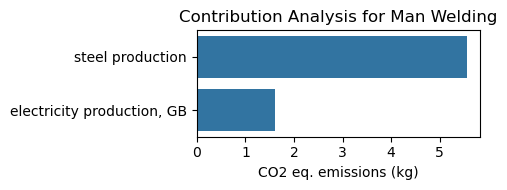

Running contribution analysis: rob_welding


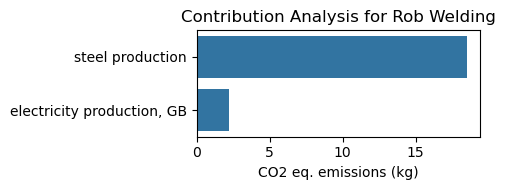

Running contribution analysis: drilling


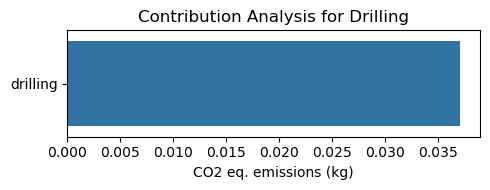

Running contribution analysis: bending


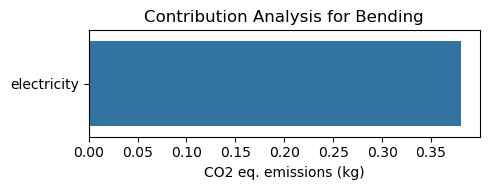

Running contribution analysis: sawing


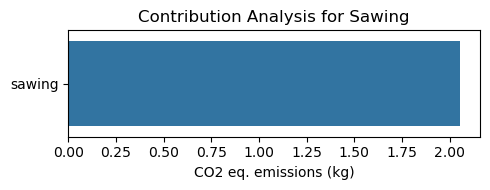

Running contribution analysis: turning


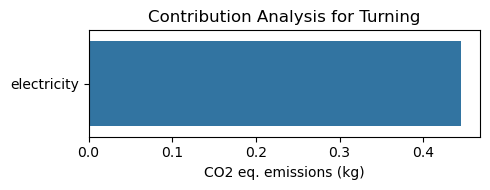

Running contribution analysis: flamecutting, lpg, meter


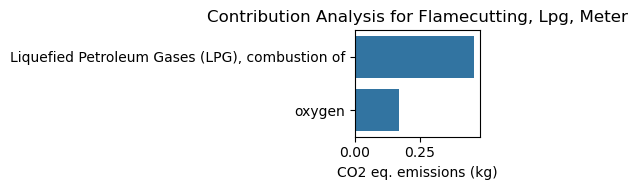

Running contribution analysis: flamecutting, natural gas,


C:\Users\TimWeber\AppData\Local\Temp\ipykernel_21480\835157069.py:24: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


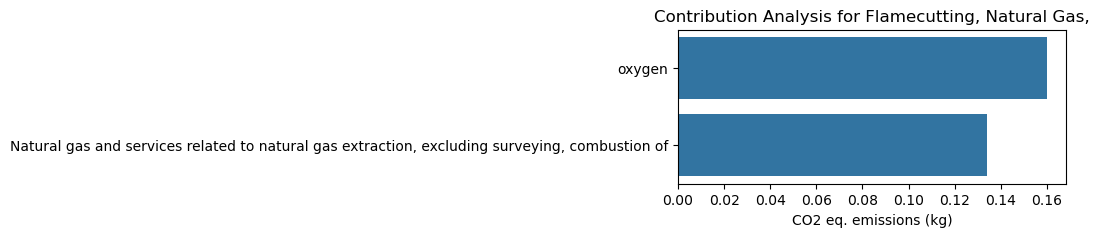

In [115]:
processes_results_ca = {}

for key, demand in machining_processes.items():
    print(f"Running contribution analysis: {key}")
    
    df = run_contribution_analysis(
        demand_object=demand,
        lcia_method=config.lcia_gwp100,
        max_level=1,
        cutoff=0.01
    )
    processes_results_ca[key] = df
    
    plot_contribution(
        df,
        title=f"Contribution Analysis for {key.replace('_', ' ').title()}"
    )

Running contribution analysis: soraluce_komatsu


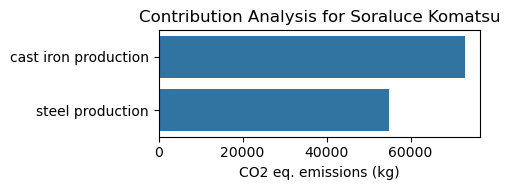

Running contribution analysis: use_case_komatsu


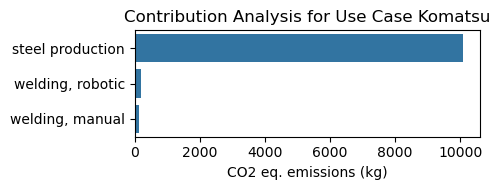

Running contribution analysis: soraluce_wwr


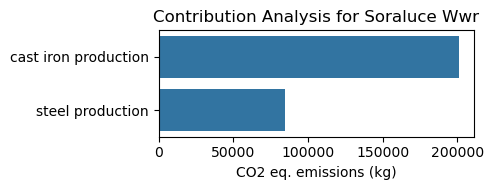

Running contribution analysis: use_case_wwr


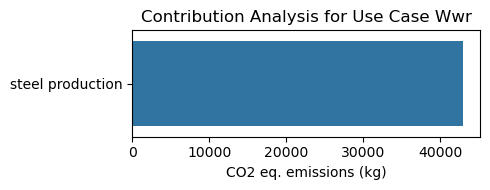

Running contribution analysis: soraluce_goimek


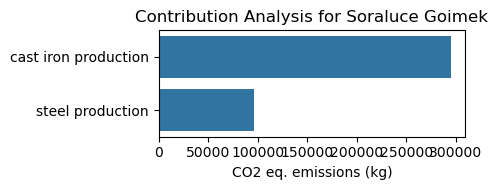

In [116]:
use_case_results_ca = {}

for key, demand in use_case_machines.items():
    print(f"Running contribution analysis: {key}")
    
    df = run_contribution_analysis(
        demand_object=demand,
        lcia_method=config.lcia_gwp100,
        max_level=1,
        cutoff=0.01
    )
    use_case_results_ca[key] = df
    
    plot_contribution(
        df,
        title=f"Contribution Analysis for {key.replace('_', ' ').title()}"
    )